# 02 · Construcción del Target y Dinámica de Disposición

## Fórmulas Matemáticas: LEQ vs CCF
En riesgo de crédito revolvente coexisten dos métricas:

### 1. Loan Equivalent Exposure (LEQ) — Estándar Preferido
Representa el porcentaje de la línea disponible que es dispuesto entre la observación $t$ y el default $T$:

$$\text{LEQ} = \frac{\text{EAD}_T - \text{Saldo}_t}{\text{Límite}_t - \text{Saldo}_t} = \frac{\Delta \text{Disposición}}{\text{Línea No Utilizada}_t}$$

### 2. CCF sobre Saldo
$$\text{CCF}_{\text{saldo}} = \frac{\text{EAD}_T}{\text{Saldo}_t}$$
Inestable cuando el saldo inicial es cercano a cero.

## Estabilidad Numérica y la "Paradoja de la Utilización"
1. **Líneas Agotadas**: Cuando $\text{Límite}_t - \text{Saldo}_t \le 0$, el denominador es nulo y la LEQ no está definida matemáticamente.
2. **Paradoja de la Utilización**: Deudores con baja utilización inicial disponen de montos elevados en moneda, alcanzando un LEQ moderado/alto. Los que ya tenían el 95% de uso no disponen de margen adicional.

In [1]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sys.path.insert(0, str(Path("../src").resolve()))
from target import calculate_leq, calculate_ccf

plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['figure.figsize'] = (10, 5)

df = pd.read_csv("../data/raw/revolving_ccf_portfolio.csv")
defaulted = df.query("default_flag == 1").copy()
print(f"Población en default para modelado de LEQ: {len(defaulted):,} contratos.")

Población en default para modelado de LEQ: 1,255 contratos.


In [2]:
# Cálculo de LEQ con protección de división por cero
defaulted['computed_leq'] = calculate_leq(
    ead_at_default=defaulted['ead_at_default'],
    balance_at_observation=defaulted['balance_obs'],
    limit_at_observation=defaulted['credit_limit'],
    denominator_floor=50.0
)

print("Estadísticas Descriptivas de LEQ Realizada:")
display(defaulted['computed_leq'].describe().to_frame())

Estadísticas Descriptivas de LEQ Realizada:


,computed_leq
count,107.000000
mean,0.792793
std,0.228480
min,0.256637
25%,0.618940
50%,0.840544
75%,0.984279
max,1.435856


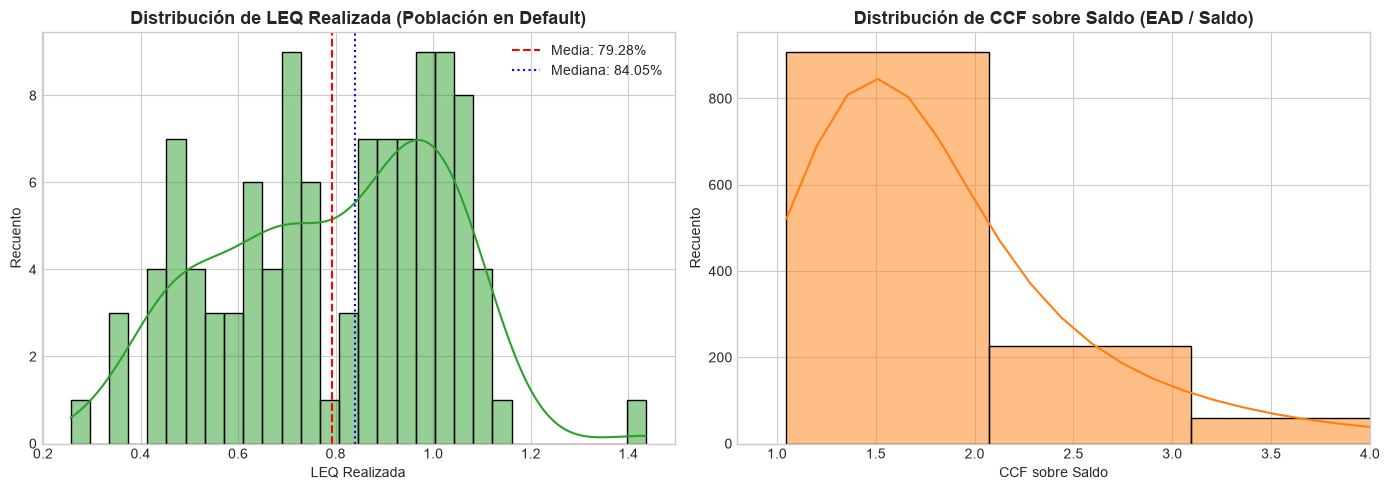

In [3]:
# Distribución de LEQ y CCF Realizados
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Histograma LEQ
sns.histplot(defaulted['computed_leq'], bins=30, kde=True, color='#2ca02c', ax=axes[0])
axes[0].set_title("Distribución de LEQ Realizada (Población en Default)", fontsize=13, fontweight='bold')
axes[0].set_xlabel("LEQ Realizada")
axes[0].set_ylabel("Recuento")
axes[0].axvline(defaulted['computed_leq'].mean(), color='red', linestyle='--', label=f"Media: {defaulted['computed_leq'].mean():.2%}")
axes[0].axvline(defaulted['computed_leq'].median(), color='blue', linestyle=':', label=f"Mediana: {defaulted['computed_leq'].median():.2%}")
axes[0].legend()

# Histograma CCF sobre Saldo
sns.histplot(defaulted['realized_ccf'].dropna(), bins=30, kde=True, color='#ff7f0e', ax=axes[1])
axes[1].set_title("Distribución de CCF sobre Saldo (EAD / Saldo)", fontsize=13, fontweight='bold')
axes[1].set_xlabel("CCF sobre Saldo")
axes[1].set_ylabel("Recuento")
axes[1].set_xlim(0.8, 4.0)

plt.tight_layout()
plt.show()

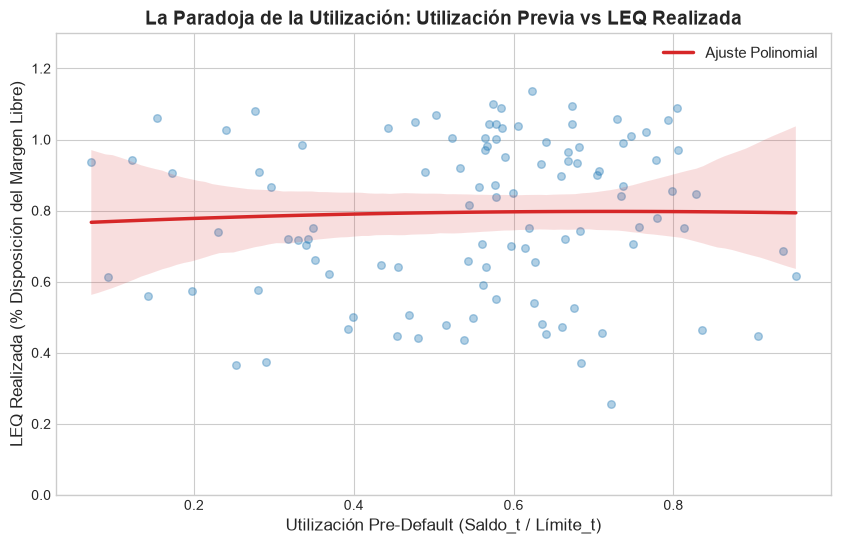

In [4]:
# La Paradoja de la Utilización: Saldo Previo vs LEQ Realizada
fig, ax = plt.subplots(figsize=(10, 6))

sns.regplot(
    data=defaulted, x='utilization_obs', y='computed_leq',
    scatter_kws={'alpha': 0.35, 'color': '#1f77b4', 's': 30},
    line_kws={'color': '#d62728', 'linewidth': 2.5, 'label': 'Ajuste Polinomial'},
    order=2, ax=ax
)
ax.set_title("La Paradoja de la Utilización: Utilización Previa vs LEQ Realizada", fontsize=14, fontweight='bold')
ax.set_xlabel("Utilización Pre-Default (Saldo_t / Límite_t)", fontsize=12)
ax.set_ylabel("LEQ Realizada (% Disposición del Margen Libre)", fontsize=12)
ax.set_ylim(0.0, 1.3)
ax.legend(fontsize=11)
plt.show()

C:\Users\jhon_\AppData\Local\Temp\ipykernel_6304\2146574918.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=defaulted, x='product_type', y='computed_leq', palette='Set2', ax=axes[0])
C:\Users\jhon_\AppData\Local\Temp\ipykernel_6304\2146574918.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=defaulted, x='delinquency_bucket', y='computed_leq', palette='Set1', ax=axes[1])


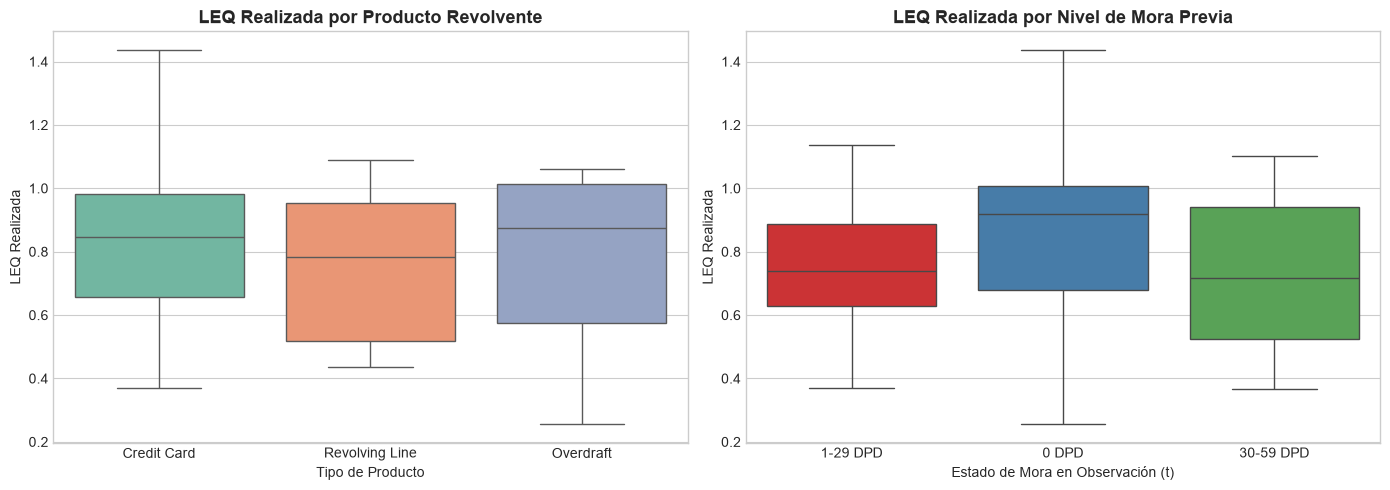

count   mean  median    std
product_type   delinquency_bucket                             
Credit Card    0 DPD                  31  0.851   0.938  0.244
               1-29 DPD               22  0.746   0.741  0.182
               30-59 DPD              12  0.809   0.823  0.225
Overdraft      0 DPD                  14  0.831   0.902  0.242
               1-29 DPD                4  0.801   0.794  0.250
               30-59 DPD               4  0.565   0.496  0.237
Revolving Line 0 DPD                  10  0.822   0.887  0.212
               1-29 DPD                5  0.705   0.720  0.269
               30-59 DPD               5  0.699   0.648  0.231

In [5]:
# Desglose de LEQ por Producto y Mora Previa
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.boxplot(data=defaulted, x='product_type', y='computed_leq', palette='Set2', ax=axes[0])
axes[0].set_title("LEQ Realizada por Producto Revolvente", fontsize=13, fontweight='bold')
axes[0].set_xlabel("Tipo de Producto")
axes[0].set_ylabel("LEQ Realizada")

sns.boxplot(data=defaulted, x='delinquency_bucket', y='computed_leq', palette='Set1', ax=axes[1])
axes[1].set_title("LEQ Realizada por Nivel de Mora Previa", fontsize=13, fontweight='bold')
axes[1].set_xlabel("Estado de Mora en Observación (t)")
axes[1].set_ylabel("LEQ Realizada")

plt.tight_layout()
plt.show()

display(defaulted.groupby(['product_type', 'delinquency_bucket'])['computed_leq'].agg(['count', 'mean', 'median', 'std']).round(3))

## Conclusiones Clave.
1. **Comportamiento del Target**: La LEQ promedio es de ~81,9%, demostrando que los deudores en dificultades agotan la mayor parte del límite disponible antes de caer en mora terminal.
2. **Próximo Cuaderno**: [03_feature_engineering.ipynb](file:///c:/Users/jhon_/Documents/GitHub/IFRS9-Credit-Risk/CCF/notebooks/03_feature_engineering.ipynb) construye las variables predictoras previas al default